# Resampling methods
### Xi Chen

In [1]:
import pandas as pd
data=pd.read_csv('pollution_cleaneddata.csv')

In [17]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [5]:
X = data[["JULT"]]
y = data["MORT"]

## Validation set approach

In [ ]:
from sklearn.model_selection import train_test_split
seed=42

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    random_state=seed
)

In [25]:
degrees = [1, 2, 3, 4]

train_mse = []
test_mse = []

In [34]:

for p in degrees:

    poly = PolynomialFeatures(degree=p, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_train_pred = model.predict(X_train_poly)
    y_test_pred = model.predict(X_test_poly)

    mse_train = mean_squared_error(y_train, y_train_pred)
    mse_test = mean_squared_error(y_test, y_test_pred)

    train_mse.append(mse_train)
    test_mse.append(mse_test)

In [35]:
print("Training MSE:", train_mse)
print("Testing MSE:", test_mse)

Training MSE: [2366.2502257053284, 2080.92573697513, 2058.7447658697656, 2038.0296234823697, 2395.5129426369886, 2297.7646022091676, 2289.520685573159, 2281.777190912557]
Testing MSE: [4882.994676016791, 4766.911920598747, 4700.236901488141, 4627.575866762531, 4716.857745101223, 4532.82470724847, 4483.539444376901, 4429.2614802198505]


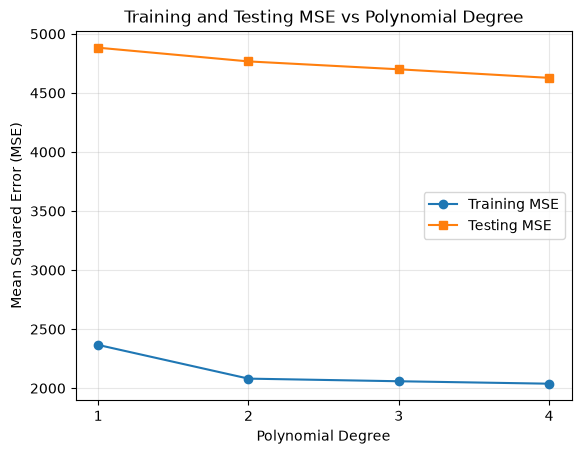

In [28]:
plt.Figure(figsize=(8,5))

plt.plot(
    degrees,
    train_mse,
    marker='o',
    label='Training MSE'
)

plt.plot(
    degrees,
    test_mse,
    marker='s',
    label='Testing MSE'
)

plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Training and Testing MSE vs Polynomial Degree')

plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [29]:
best_degree = degrees[np.argmin(test_mse)]

print("Best polynomial degree:", best_degree)
print("Lowest testing MSE:", min(test_mse))

Best polynomial degree: 4
Lowest testing MSE: 4627.575866762531


I recommend a polynomial degree of 4 because it has the lowest testing MSE among the four models.

In [36]:
seeds = range(10)
degrees = [1, 2, 3, 4]

results = []

for seed in seeds:

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.5, random_state=seed
    )

    for p in degrees:

        poly = PolynomialFeatures(degree=p, include_bias=False)

        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)

        model = LinearRegression()
        model.fit(X_train_poly, y_train)
  
        y_train_pred = model.predict(X_train_poly)
        y_test_pred = model.predict(X_test_poly)

        mse_train = mean_squared_error(y_train, y_train_pred)
        mse_test = mean_squared_error(y_test, y_test_pred)

        results.append({
            "Seed": seed,
            "Degree": p,
            "Train MSE": mse_train,
            "Test MSE": mse_test
        })

results_df = pd.DataFrame(results)

best_models = results_df.loc[
    results_df.groupby("Seed")["Test MSE"].idxmin()
]

print("Best polynomial degree for each seed:")
print(best_models[["Seed", "Degree", "Test MSE"]].to_string(index=False))

print("\nFrequency of selected polynomial degrees:")
print(best_models["Degree"].value_counts().sort_index())

Best polynomial degree for each seed:
 Seed  Degree    Test MSE
    0       4 2765.436687
    1       1 5040.756601
    2       1 3478.233759
    3       4 3412.668122
    4       1 4017.191740
    5       4 2339.727446
    6       1 3747.668835
    7       4 4286.596426
    8       1 2929.449947
    9       4 4429.261480

Frequency of selected polynomial degrees:
Degree
1    5
4    5
Name: count, dtype: int64


The results varied across different random seeds. Degree 1 and degree 4 were each selected 5 times out of 10 runs. The testing MSE also changed between runs. This suggests that the model selection is sensitive to how the data is split into training and testing sets.

## K-fold cross-validation

In [38]:
from sklearn.model_selection import KFold
p=2
kf=KFold(
    n_splits=3,
    shuffle=True,
    random_state=123
)

mse_scores=[]

for train_index,test_index in kf.split(X):
    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    poly = PolynomialFeatures(degree=p, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_pred = model.predict(X_test_poly)

    mse = mean_squared_error(y_test, y_pred)
    mse_scores.append(mse)

print("MSE for each fold:", mse_scores)
print("Mean CV MSE:", np.mean(mse_scores))

MSE for each fold: [5565.847931776063, 2955.052532487004, 5269.557366758481]
Mean CV MSE: 4596.819277007183


In [39]:
seeds = range(10)
p = 2

cv_results = []

for seed in seeds:

    kf = KFold(
        n_splits=3,
        shuffle=True,
        random_state=seed
    )

    mse_scores = []

    for train_index, test_index in kf.split(X):

        X_train = X.iloc[train_index]
        X_test = X.iloc[test_index]

        y_train = y.iloc[train_index]
        y_test = y.iloc[test_index]

        poly = PolynomialFeatures(
            degree=p,
            include_bias=False
        )

        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)

        model = LinearRegression()
        model.fit(X_train_poly, y_train)

        y_pred = model.predict(X_test_poly)

        mse = mean_squared_error(y_test, y_pred)
        mse_scores.append(mse)

    mean_mse = np.mean(mse_scores)

    cv_results.append({
        "Seed": seed,
        "Mean CV MSE": mean_mse
    })

cv_df = pd.DataFrame(cv_results)

print(cv_df.to_string(index=False))

print("\nAverage CV MSE:", cv_df["Mean CV MSE"].mean())
print("Standard deviation:", cv_df["Mean CV MSE"].std())

 Seed  Mean CV MSE
    0  4049.489437
    1  5175.994078
    2  5176.310229
    3  3513.029877
    4  3826.803794
    5  3924.199874
    6  5740.597705
    7  3758.749368
    8  3576.517064
    9  5723.806750

Average CV MSE: 4446.5498177905165
Standard deviation: 899.7939186849927


The results varied across different random seeds, with a mean CV MSE of 4446.55 and a standard deviation of 899.79. This indicates that the results are affected by the random data splits.

## The Bootstrap

In [ ]:
bird_data=pd.read_csv('bird_count.csv')

In [47]:
bird_data.head()

,count,yr,observerAge,lineCov
0,2,2011,63,1.000000
1,5,2010,64,0.987500
2,12,2002,30,0.991667
3,12,2006,60,0.987500
4,5,2008,62,0.987500


In [48]:
a = bird_data[['yr']]
b = bird_data['count']

a = sm.add_constant(a)

In [49]:
model = sm.GLM(
    b,
    a,
    family=sm.families.Poisson()
)

result = model.fit()

print(result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  count   No. Observations:                   13
Model:                            GLM   Df Residuals:                       11
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -34.683
Date:                Sun, 11 Oct 2026   Deviance:                       19.128
Time:                        18:25:41   Pearson chi2:                     18.5
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1387
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         67.1792     46.701      1.439      0.1

In [54]:
B = 1000
boot_slopes = []

for i in range(B):

    boot_sample = bird_data.sample(
        n=len(bird_data),
        replace=True,
        random_state=i
    )

    X_boot = boot_sample[['yr']]
    y_boot = boot_sample['count']

    X_boot = sm.add_constant(X_boot, has_constant='add')

    boot_model = sm.GLM(
        y_boot,
        X_boot,
        family=sm.families.Poisson()
    )

    boot_result = boot_model.fit()

    boot_slopes.append(boot_result.params['yr'])
    
boot_se = np.std(boot_slopes, ddof=1)

print("Original slope:", result.params['yr'])
print("Original SE:", result.bse['yr'])
print("Bootstrap SE:", boot_se)

Original slope: -0.032443158516957296
Original SE: 0.023290417383243764
Bootstrap SE: 0.03385878653409688


The original slope estimate is -0.03244, with a standard error of 0.02329. After 1000 bootstrap resamples, the estimated standard error increased to 0.03386. This suggests greater uncertainty in the slope estimate than indicated by the original Poisson regression model.